In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('Unemployment in India.csv')
print(df.shape)
print(list(df.columns))
df.head()

(768, 7)
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [20]:
# remove stray spaces from column names and text values
df.columns = df.columns.str.strip()
df['Region'] = df['Region'].str.strip()

# shorter column names
df = df.rename(columns={
    'Estimated Unemployment Rate (%)': 'Unemployment_Rate',
    'Estimated Employed': 'Employed',
    'Estimated Labour Participation Rate (%)': 'Labour_Participation',
})

# convert the Date column from text to real dates
df['Date'] = pd.to_datetime(df['Date'].str.strip(), dayfirst=True)

# checks
print(df.dtypes)
print()
print("Missing values:")
print(df.isnull().sum())
print()
print("Date range:", df['Date'].min(), "to", df['Date'].max())
df.head()

Region                          object
Date                    datetime64[ns]
Frequency                       object
Unemployment_Rate              float64
Employed                       float64
Labour_Participation           float64
Area                            object
dtype: object

Missing values:
Region                  28
Date                    28
Frequency               28
Unemployment_Rate       28
Employed                28
Labour_Participation    28
Area                    28
dtype: int64

Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


,Region,Date,Frequency,Unemployment_Rate,Employed,Labour_Participation,Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


In [21]:
print("Rows before:", len(df))
df = df.dropna(how='all').reset_index(drop=True)
print("Rows after:", len(df))
print()
print(df.isnull().sum())

Rows before: 768
Rows after: 740

Region                  0
Date                    0
Frequency               0
Unemployment_Rate       0
Employed                0
Labour_Participation    0
Area                    0
dtype: int64


### Data Cleaning
- Stripped extra spaces from the column names and Region values, and renamed the long column names.
- Converted Date from text to a datetime type.
- Found 28 rows that were completely empty (all columns missing), so dropped them. Because the rows were entirely blank, no imputation was needed.

In [22]:
df.describe()

,Date,Unemployment_Rate,Employed,Labour_Participation
count,740,740.000000,7.400000e+02,740.000000
mean,2019-12-12 18:36:58.378378496,11.787946,7.204460e+06,42.630122
min,2019-05-31 00:00:00,0.000000,4.942000e+04,13.330000
25%,2019-08-31 00:00:00,4.657500,1.190404e+06,38.062500
50%,2019-11-30 00:00:00,8.350000,4.744178e+06,41.160000
75%,2020-03-31 00:00:00,15.887500,1.127549e+07,45.505000
max,2020-06-30 00:00:00,76.740000,4.577751e+07,72.570000
std,NaN,10.721298,8.087988e+06,8.111094


In [23]:
region_avg = df.groupby('Region')['Unemployment_Rate'].mean().sort_values(ascending=False).round(2)
print(region_avg)

Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: Unemployment_Rate, dtype: float64


In [24]:
monthly = df.groupby('Date')['Unemployment_Rate'].mean().round(2)
print(monthly)

Date
2019-05-31     8.87
2019-06-30     9.30
2019-07-31     9.03
2019-08-31     9.64
2019-09-30     9.05
2019-10-31     9.90
2019-11-30     9.87
2019-12-31     9.50
2020-01-31     9.95
2020-02-29     9.96
2020-03-31    10.70
2020-04-30    23.64
2020-05-31    24.88
2020-06-30    11.90
Name: Unemployment_Rate, dtype: float64


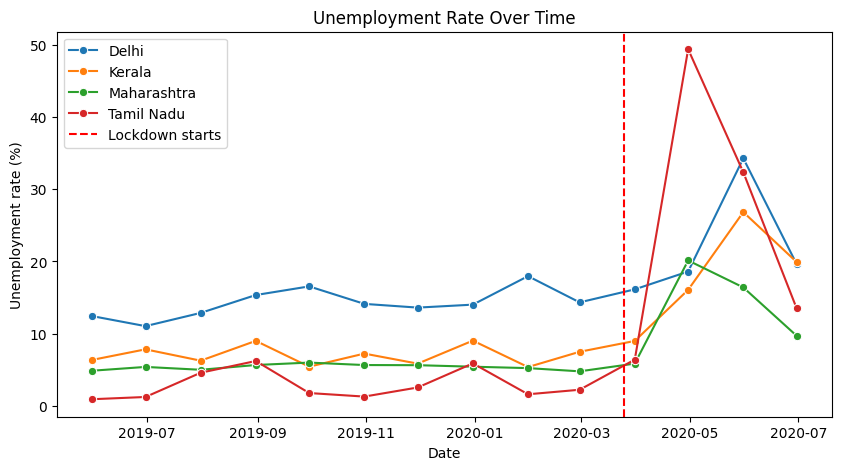

In [25]:
states = ['Maharashtra', 'Delhi', 'Tamil Nadu', 'Kerala']
trend = (df[df['Region'].isin(states)]
         .groupby(['Date', 'Region'])['Unemployment_Rate'].mean().reset_index())

plt.figure(figsize=(10, 5))
sns.lineplot(data=trend, x='Date', y='Unemployment_Rate', hue='Region', marker='o')
plt.axvline(pd.Timestamp('2020-03-25'), color='red', linestyle='--', label='Lockdown starts')
plt.title('Unemployment Rate Over Time')
plt.ylabel('Unemployment rate (%)')
plt.legend()
plt.show()

**Observation:** Unemployment was fairly stable in all four states until the lockdown (red line, late March 2020), then rose sharply. Tamil Nadu peaked at about 49% in May 2020, while Delhi and Kerala peaked in June at about 34% and 27%. Most states had started to come down by July 2020, but rates were still well above their pre-lockdown levels in Delhi and Kerala.

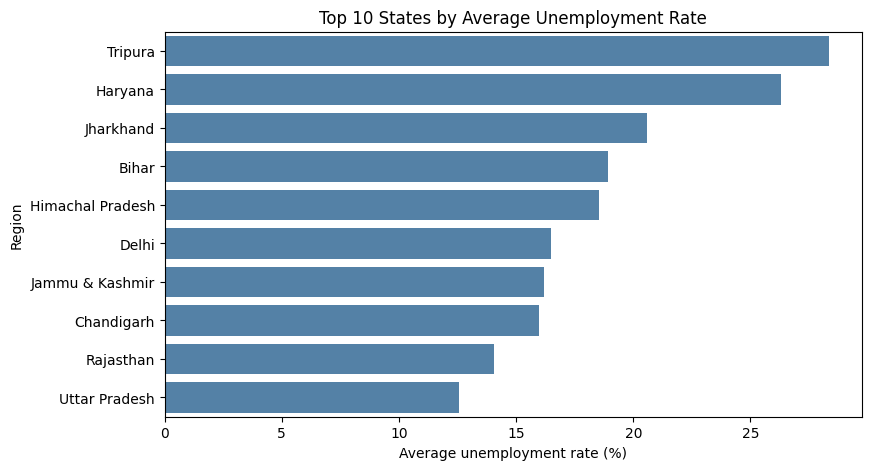

In [26]:
top10 = df.groupby('Region')['Unemployment_Rate'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=top10.values, y=top10.index, color='steelblue')
plt.xlabel('Average unemployment rate (%)')
plt.title('Top 10 States by Average Unemployment Rate')
plt.show()

**Observation:** Tripura and Haryana have the highest average unemployment rates (about 28% and 26%), followed by Jharkhand, Bihar and Himachal Pradesh. These averages cover both the pre- and post-lockdown months, so they are partly pulled up by the 2020 spike.

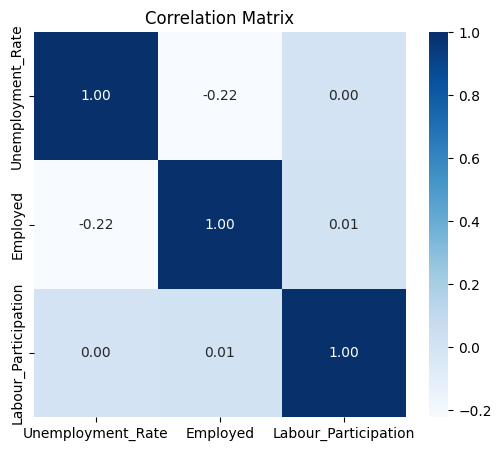

In [27]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Unemployment_Rate', 'Employed', 'Labour_Participation']].corr(),
            annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

**Observation:** Labour participation has almost no linear correlation with either the unemployment rate (about 0.00) or the number of people employed (about 0.01). This is partly because the Employed column is an absolute headcount, so it varies mainly with the size of each state, not with how the labour market is doing. The heatmap therefore shows that no single one of these three measures is explained by the others, and the clearest changes in this dataset come from the time-series and pre vs post comparisons, not from correlations.

In [28]:
df[['Unemployment_Rate', 'Employed', 'Labour_Participation']].corr().round(2)

,Unemployment_Rate,Employed,Labour_Participation
Unemployment_Rate,1.00,-0.22,0.00
Employed,-0.22,1.00,0.01
Labour_Participation,0.00,0.01,1.00


            Unemployment_Rate    Employed  Labour_Participation
Period                                                         
Post-COVID              17.77  6517203.34                 39.33
Pre-COVID                9.51  7466027.87                 43.89


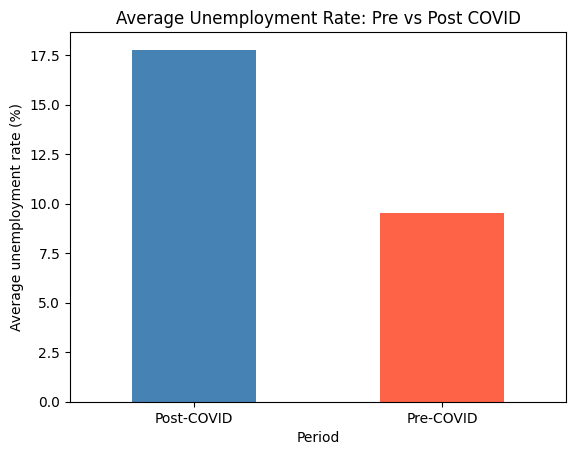

In [29]:
cutoff = pd.Timestamp('2020-03-25')   # start of India's national lockdown
df['Period'] = np.where(df['Date'] < cutoff, 'Pre-COVID', 'Post-COVID')

comparison = df.groupby('Period')[['Unemployment_Rate', 'Employed', 'Labour_Participation']].mean().round(2)
print(comparison)

comparison['Unemployment_Rate'].plot(kind='bar', color=['steelblue', 'tomato'], rot=0)
plt.ylabel('Average unemployment rate (%)')
plt.title('Average Unemployment Rate: Pre vs Post COVID')
plt.show()

**Observation:** The average unemployment rate rose from 9.51% before the lockdown to 17.77% after it, an increase of about 8 percentage points. The average number of people employed fell by about 13%, from roughly 7.47 million to 6.52 million. Note that the post-COVID period covers only about three months (April to June 2020), against roughly ten months before, so the comparison is a snapshot and not a long-term trend.

### Conclusion
The data shows a clear shock after India's national lockdown began in late March 2020. Unemployment roughly doubled on average and employment fell, with some states hit far harder than others. Because the dataset ends in June 2020, we cannot say how quickly the recovery continued.